PART A: GRADIENT DESCENT
Epoch 0: Loss = 56104831989.8725
Epoch 200: Loss = 5626972012.5788
Epoch 400: Loss = 5250442442.4515
Epoch 600: Loss = 5066947735.2381
Epoch 800: Loss = 4970550862.8041
Epoch 1000: Loss = 4918801314.3763
Epoch 1200: Loss = 4890489839.2582
Epoch 1400: Loss = 4874715658.5911
Epoch 1600: Loss = 4865759916.8817
Epoch 1800: Loss = 4860572964.6472

MSE: 4857504699.8307
RMSE: 69695.8012
NE (Normalized Error): 0.1437


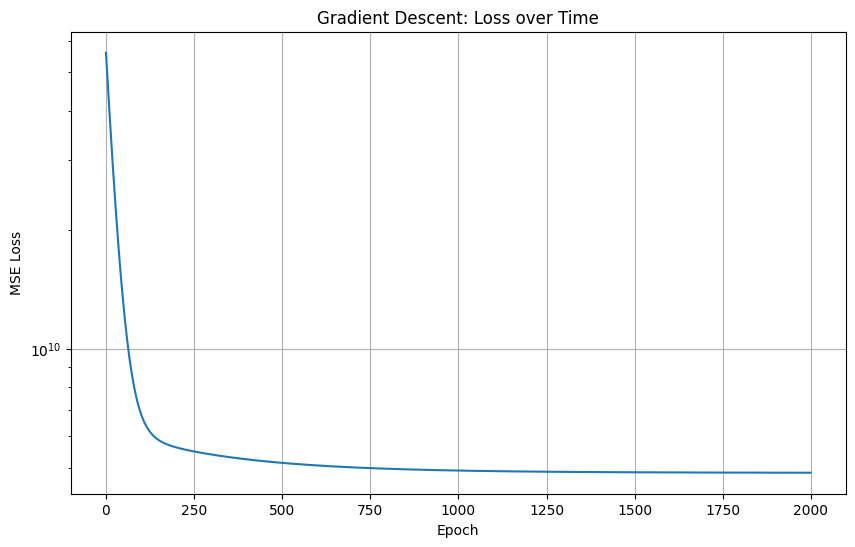


PART B: NORMAL EQUATION

MSE: 4852263483.6438
RMSE: 69658.1904
NE (Normalized Error): 0.1436

PART C: COMPARISON

Weight similarity: 0.998580
(Close to 1.0 means both methods found similar solutions)

R² Score (GD): 0.6352
R² Score (NE): 0.6356

Example Prediction for sample 0:
GD Prediction: 409594.65
NE Prediction: 408844.67
True value: 452600.00

PART E: LEARNING RATE EFFECTS
Epoch 0: Loss = 56104831989.8725
Epoch 0: Loss = 56104831989.8725
Epoch 0: Loss = 56104831989.8725


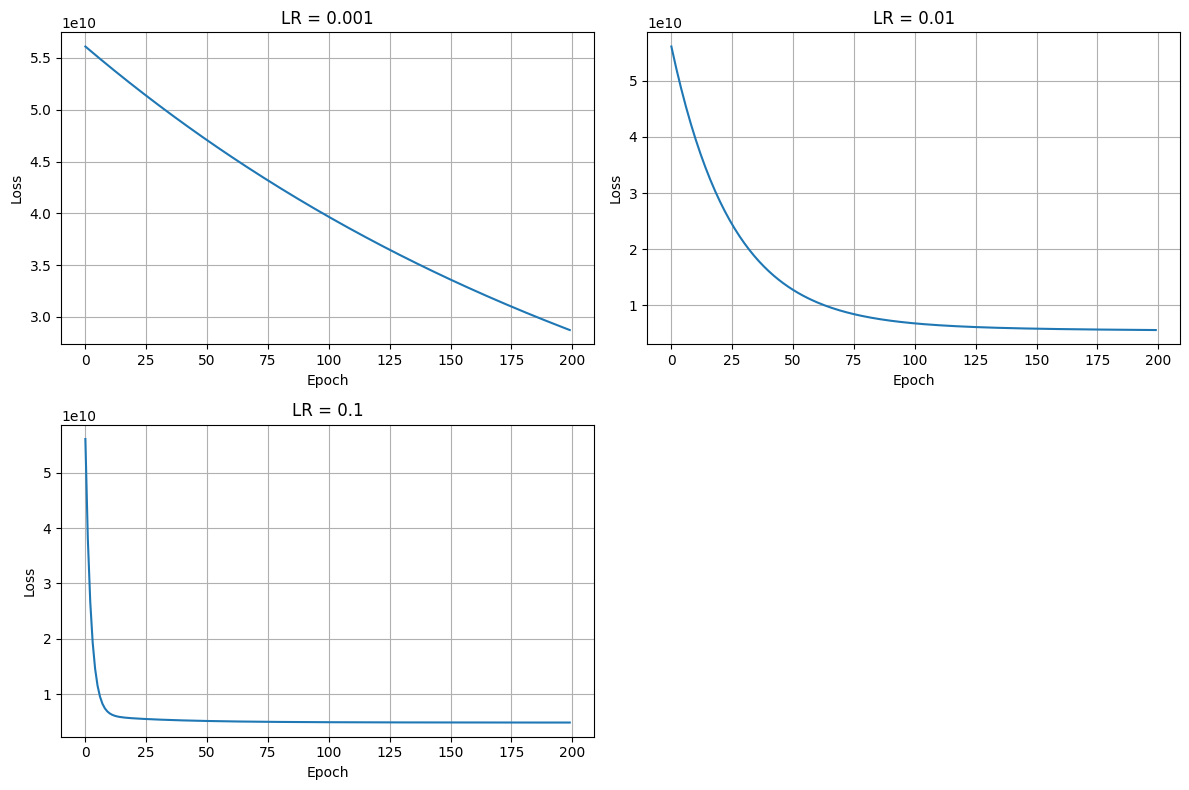

In [ ]:
from LinearRegression import LinearRegression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load California Housing data
df = pd.read_csv("housing.csv")

# Drop categorical column
df = df.drop(columns=['ocean_proximity'])

# Fix missing values
df = df.fillna(df.median())

# Features and target
X = df.drop("median_house_value", axis=1).values.astype(float)
y = df["median_house_value"].values.astype(float)

# Normalize features
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)
X = (X - X_mean) / X_std

print("="*50)
print("PART A: GRADIENT DESCENT")
print("="*50)

# Train with Gradient Descent
model_gd = LinearRegression(method="gradient_descent")
model_gd.fit(X, y, epochs=2000, lr=0.01)

y_pred_gd = model_gd.predict(X)

# Evaluate
mse_gd = np.mean((y - y_pred_gd) ** 2)
rmse_gd = np.sqrt(mse_gd)
ne_gd = rmse_gd / (y.max() - y.min())

print(f"\nMSE: {mse_gd:.4f}")
print(f"RMSE: {rmse_gd:.4f}")
print(f"NE (Normalized Error): {ne_gd:.4f}")

# Loss plot
plt.figure(figsize=(10, 6))
plt.plot(model_gd.loss_history)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Gradient Descent: Loss over Time')
plt.yscale('log')
plt.grid(True)
plt.savefig('gd_loss.png')
plt.show()

print("\n" + "="*50)
print("PART B: NORMAL EQUATION")
print("="*50)

# Train with Normal Equation
model_ne = LinearRegression(method="normal_equation")
model_ne.fit(X, y)

y_pred_ne = model_ne.predict(X)

# Evaluate
mse_ne = np.mean((y - y_pred_ne) ** 2)
rmse_ne = np.sqrt(mse_ne)
ne_ne = rmse_ne / (y.max() - y.min())

print(f"\nMSE: {mse_ne:.4f}")
print(f"RMSE: {rmse_ne:.4f}")
print(f"NE (Normalized Error): {ne_ne:.4f}")

print("\n" + "="*50)
print("PART C: COMPARISON")
print("="*50)

# 1. Weight similarity
w_gd = model_gd.W.flatten()
w_ne = model_ne.W.flatten()

normalized_inner_product = np.dot(w_gd, w_ne) / (
    np.linalg.norm(w_gd) * np.linalg.norm(w_ne)
)

print(f"\nWeight similarity: {normalized_inner_product:.6f}")
print("(Close to 1.0 means both methods found similar solutions)")

# 2. R2 Score
def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

print(f"\nR² Score (GD): {r2_score(y, y_pred_gd):.4f}")
print(f"R² Score (NE): {r2_score(y, y_pred_ne):.4f}")

# 3. Example prediction
idx = 0
print(f"\nExample Prediction for sample {idx}:")
print(f"GD Prediction: {model_gd.predict(X[idx:idx+1])[0]:.2f}")
print(f"NE Prediction: {model_ne.predict(X[idx:idx+1])[0]:.2f}")
print(f"True value: {y[idx]:.2f}")

print("\n" + "="*50)
print("PART E: LEARNING RATE EFFECTS")
print("="*50)

# Test different learning rates
learning_rates = [0.001, 0.01, 0.1]
plt.figure(figsize=(12, 8))

for i, lr in enumerate(learning_rates):
    model = LinearRegression(method="gradient_descent")
    model.fit(X, y, epochs=200, lr=lr)
    
    plt.subplot(2, 2, i+1)
    plt.plot(model.loss_history)
    plt.title(f'LR = {lr}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True)

plt.tight_layout()
plt.savefig('learning_rates.png')
plt.show()